# Evaluating a structural causal model

A structural causal model assigns one autonomous equation to every variable:

$$
X_j=f_j\!\left(\operatorname{pa}_j,U_j\right),
\qquad j=1,\ldots,p.
$$

Here, $X_j$ is variable $j$, $f_j$ is its supplied structural mechanism, $\operatorname{pa}_j$ is the vector of parent values entering that mechanism, $U_j$ is its outside input, and $p$ is the number of variables.

,Node,Parents in lexical order,Equation
0,X,None,X = U_X
1,M,X,M = 0.8 X + U_M
2,Y,"M, X",Y = 0.7 M + 0.4 X + U_Y


,Node,Mean,Standard deviation,Minimum,Maximum
0,X,0.09261,0.968548,-2.544639,2.846806
1,M,0.063516,0.983941,-2.629414,3.533665
2,Y,0.07219,1.213148,-3.214942,3.180103


,Check,Observed,Passed
0,Canonical node order,"X, M, Y",True
1,Hand and public values agree,0,True
2,Returned values are protected,False,True


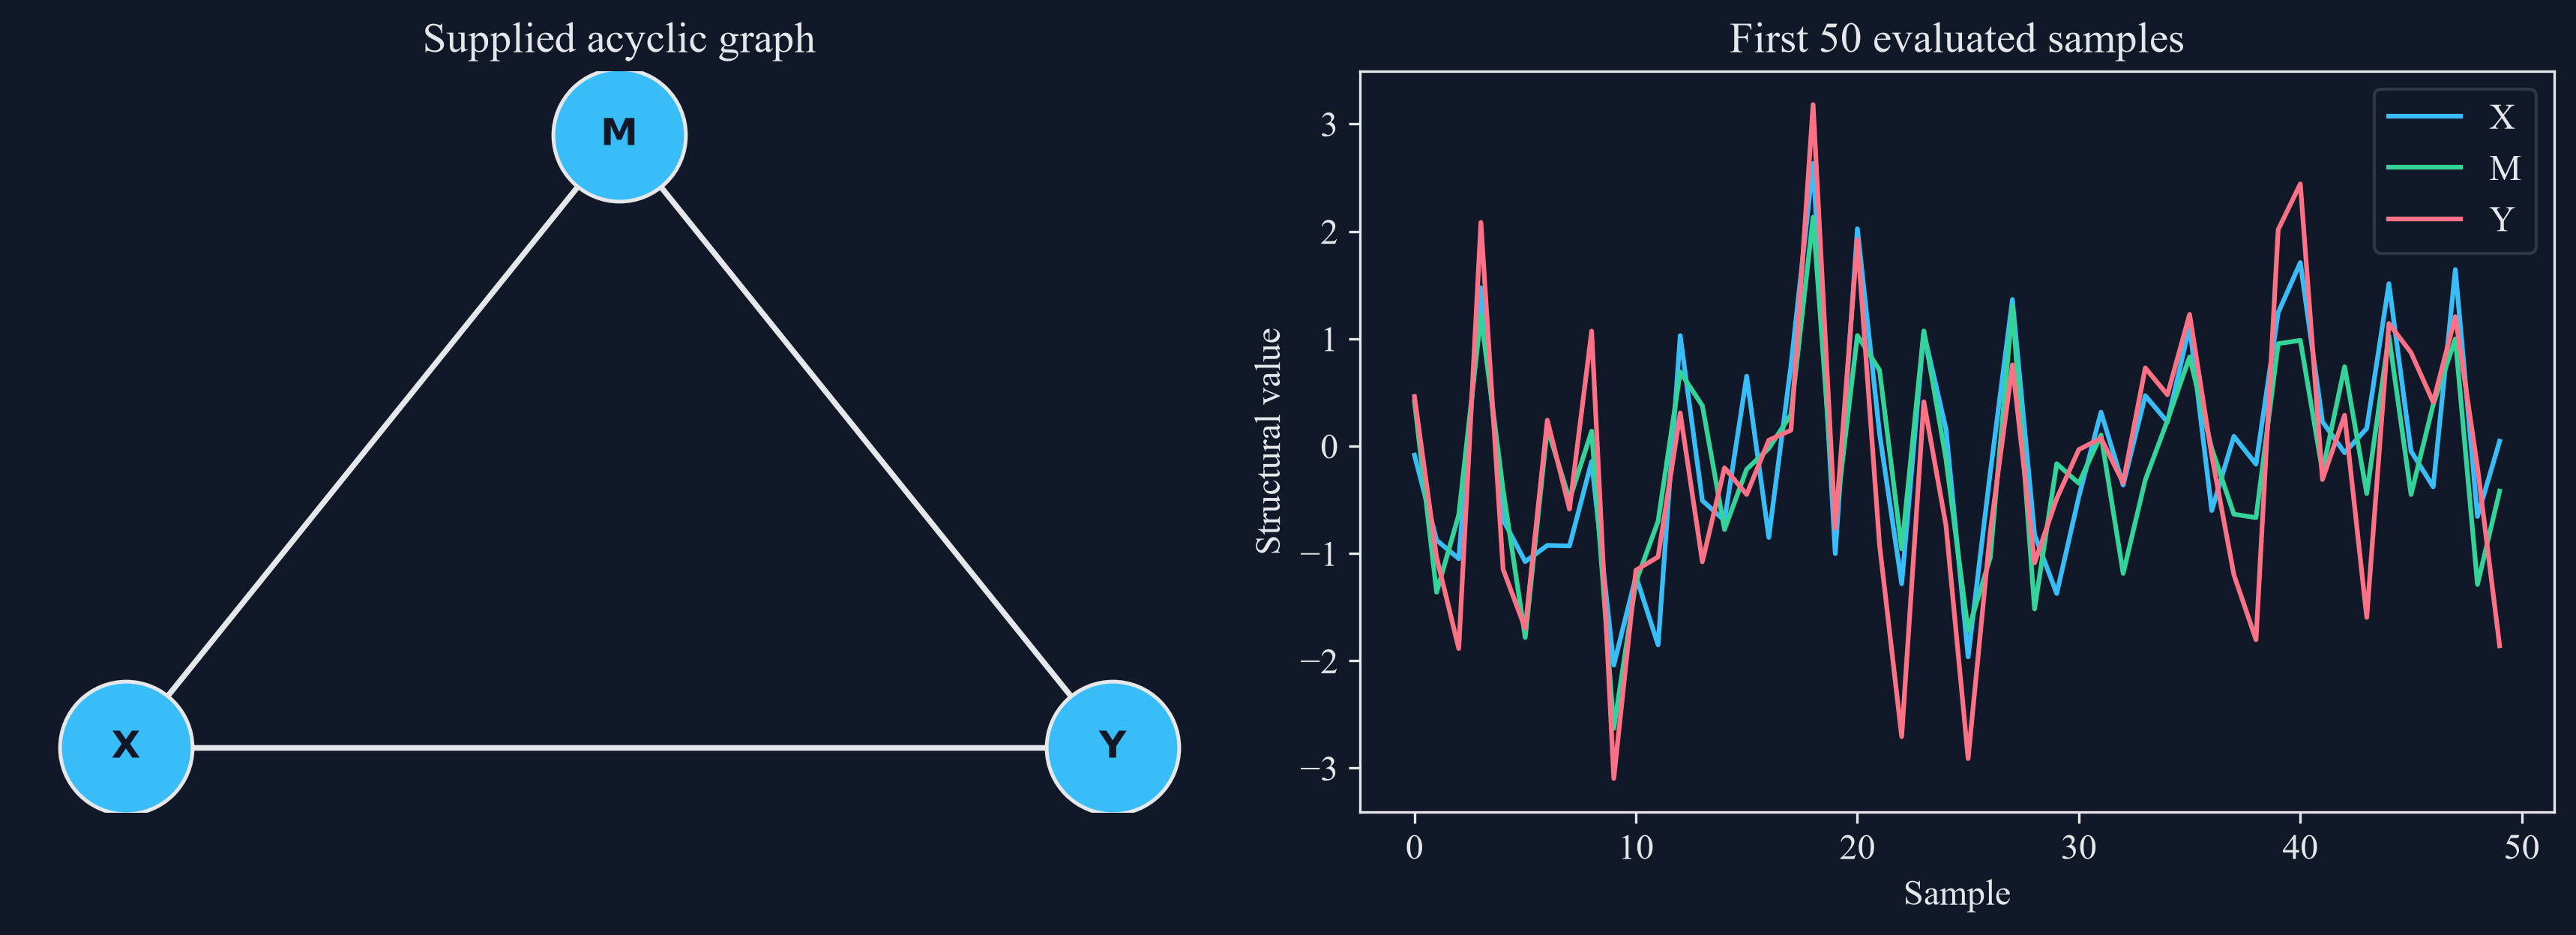

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
import re
import sys
import warnings
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import Image

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parents[1]

from RiskLabAI.causal_factor_analysis import CausalDAG, DifferenceInDifferencesEstimate, StructuralCausalModelResult, TreatmentEffectDecomposition, average_treatment_effect, backdoor_adjusted_average_treatment_effect, backdoor_adjusted_expectation, difference_in_differences, evaluate_structural_causal_model, frontdoor_adjusted_probability, linear_instrumental_variable_effect, randomized_mean_difference, treatment_effect_decomposition

FIGURES = ROOT / "outputs" / "figures" / "03_structural_treatment_effects"
TABLES = ROOT / "outputs" / "tables" / "03_structural_treatment_effects"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {"background": "#111827", "axes": "#111827", "text": "#E5E7EB", "cyan": "#38BDF8", "amber": "#FBBF24", "green": "#34D399", "rose": "#FB7185", "violet": "#C084FC", "grid": "#374151", "muted": "#94A3B8"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def display_float(value):
    if not np.isfinite(value):
        return str(value)
    nearest_integer = round(float(value))
    if np.isclose(value, nearest_integer, atol=1e-12):
        return str(int(nearest_integer))
    if abs(value) < 5e-13:
        return "0"
    return f"{value:.6f}".rstrip("0").rstrip(".")

pd.set_option("display.float_format", display_float)

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True, position="tbp"):
    table_frame = frame.copy()
    for column in table_frame.columns:
        if pd.api.types.is_bool_dtype(table_frame[column]):
            table_frame[column] = table_frame[column].map({True: "Yes", False: "No"})
    table_frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(table_frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position=position))
    if fit:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{adjustbox}{max width=\textwidth}" + "\n" + r"\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}" + "\n" + r"\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    latex = re.sub(r"(?<![A-Za-z])(?:nan|NaN)(?![A-Za-z])", "Not available", latex)
    latex = re.sub(r"(?<![A-Za-z])inf(?![A-Za-z])", "No finite value", latex)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def save_figure(figure, stem):
    figure.savefig(FIGURES / f"{stem}.png", bbox_inches="tight", dpi=300)
    figure.savefig(FIGURES / f"{stem}.pdf", bbox_inches="tight")
    display(Image(filename=str(FIGURES / f"{stem}.png")))
    plt.close(figure)

def ols_coefficient(outcome, treatment, controls=None):
    columns = [np.asarray(treatment, dtype=float)]
    if controls is not None:
        values = np.asarray(controls, dtype=float)
        if values.ndim == 1:
            values = values.reshape(-1, 1)
        columns.extend(values[:, index] for index in range(values.shape[1]))
    design = np.column_stack([np.ones(len(outcome))] + columns)
    return float(np.linalg.lstsq(design, np.asarray(outcome, dtype=float), rcond=None)[0][1])

def contract_result(name, action, expected):
    try:
        action()
        return {"Check": name, "Expected result": expected, "Observed result": "Accepted", "Passed": False}
    except Exception as error:
        return {"Check": name, "Expected result": expected, "Observed result": type(error).__name__, "Passed": type(error).__name__ == expected}

def draw_dag(axis, dag, positions, title):
    graph = nx.DiGraph(dag.directed_edges)
    graph.add_nodes_from(dag.nodes)
    nx.draw_networkx_nodes(graph, positions, ax=axis, node_color=palette["cyan"], node_size=1800, edgecolors=palette["text"], linewidths=1.2)
    nx.draw_networkx_labels(graph, positions, ax=axis, font_color=palette["background"], font_weight="bold")
    nx.draw_networkx_edges(graph, positions, ax=axis, edge_color=palette["text"], width=1.8, arrows=True, arrowsize=20)
    axis.set_title(title)
    axis.set_axis_off()

rng = np.random.default_rng(256001)
sample_size = 500
chain_dag = CausalDAG(("M", "X", "Y"), (("X", "M"), ("M", "Y"), ("X", "Y")), ("M", "X", "Y"))
chain_exogenous = {"X": rng.normal(size=sample_size), "M": rng.normal(scale=0.6, size=sample_size), "Y": rng.normal(scale=0.7, size=sample_size)}
chain_mechanisms = {
    "X": lambda parents, noise: noise,
    "M": lambda parents, noise: 0.8 * parents[:, 0] + noise,
    "Y": lambda parents, noise: 0.7 * parents[:, 0] + 0.4 * parents[:, 1] + noise,
}
chain_result = evaluate_structural_causal_model(chain_dag, chain_mechanisms, chain_exogenous)
chain_frame = pd.DataFrame(chain_result.values, columns=chain_result.node_order)
manual_x = chain_exogenous["X"]
manual_m = 0.8 * manual_x + chain_exogenous["M"]
manual_y = 0.7 * manual_m + 0.4 * manual_x + chain_exogenous["Y"]
manual_values = np.column_stack((manual_x, manual_m, manual_y))
chain_specification = pd.DataFrame([
    {"Node": "X", "Parents in lexical order": "None", "Equation": "X = U_X"},
    {"Node": "M", "Parents in lexical order": "X", "Equation": "M = 0.8 X + U_M"},
    {"Node": "Y", "Parents in lexical order": "M, X", "Equation": "Y = 0.7 M + 0.4 X + U_Y"},
])
chain_summary = chain_frame.agg(["mean", "std", "min", "max"]).T.reset_index().rename(columns={"index": "Node", "mean": "Mean", "std": "Standard deviation", "min": "Minimum", "max": "Maximum"})
chain_check = pd.DataFrame([
    {"Check": "Canonical node order", "Observed": ", ".join(chain_result.node_order), "Passed": chain_result.node_order == ("X", "M", "Y")},
    {"Check": "Hand and public values agree", "Observed": np.max(np.abs(chain_result.values - manual_values)), "Passed": np.allclose(chain_result.values, manual_values)},
    {"Check": "Returned values are protected", "Observed": str(chain_result.values.flags.writeable), "Passed": not chain_result.values.flags.writeable},
])
save_table(chain_specification, "scm_chain_specification", "Structural equations and lexical parent order for the three-node model.", "tab:chapter25-scm-chain-specification")
save_table(chain_summary, "scm_chain_summary", "Summary of values produced by the structural equations.", "tab:chapter25-scm-chain-summary")
save_table(chain_check, "scm_chain_checks", "Hand calculation, order, and protection checks.", "tab:chapter25-scm-chain-checks")
display(chain_specification)
display(chain_summary)
display(chain_check)

positions = {"X": (0, 0), "M": (1.2, 0.7), "Y": (2.4, 0)}
figure, axes = plt.subplots(1, 2, figsize=(11.6, 4.3))
draw_dag(axes[0], chain_dag, positions, "Supplied acyclic graph")
draw_rows = np.arange(50)
axes[1].plot(draw_rows, chain_frame.loc[draw_rows, "X"], color=palette["cyan"], label="X")
axes[1].plot(draw_rows, chain_frame.loc[draw_rows, "M"], color=palette["green"], label="M")
axes[1].plot(draw_rows, chain_frame.loc[draw_rows, "Y"], color=palette["rose"], label="Y")
axes[1].set_xlabel("Sample")
axes[1].set_ylabel("Structural value")
axes[1].set_title("First 50 evaluated samples")
axes[1].legend()
figure.tight_layout()
save_figure(figure, "scm_chain_graph_and_values")
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#111827", "axes.facecolor": "#111827", "axes.edgecolor": "#94A3B8", "axes.labelcolor": "#E5E7EB", "axes.titlecolor": "#E5E7EB", "axes.titleweight": "bold", "xtick.color": "#94A3B8", "ytick.color": "#94A3B8", "text.color": "#E5E7EB", "grid.color": "#374151", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#111827", "legend.edgecolor": "#374151", "legend.framealpha": 0.96, "savefig.facecolor": "#111827", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Order is determined by the graph

For every arrow $X_k\to X_j$, evaluation must respect the order condition:

$$
\operatorname{ord}(X_k)<\operatorname{ord}(X_j).
$$

Here, $X_k$ is a parent, $X_j$ is its child, and $\operatorname{ord}(X)$ is the position at which a node is evaluated; lexical order resolves ties among nodes that are simultaneously ready.

,Position,Node
0,1,A
1,2,B
2,3,C
3,4,D


,Parent A,Parent B,D result
0,1,20,201
1,2,21,212


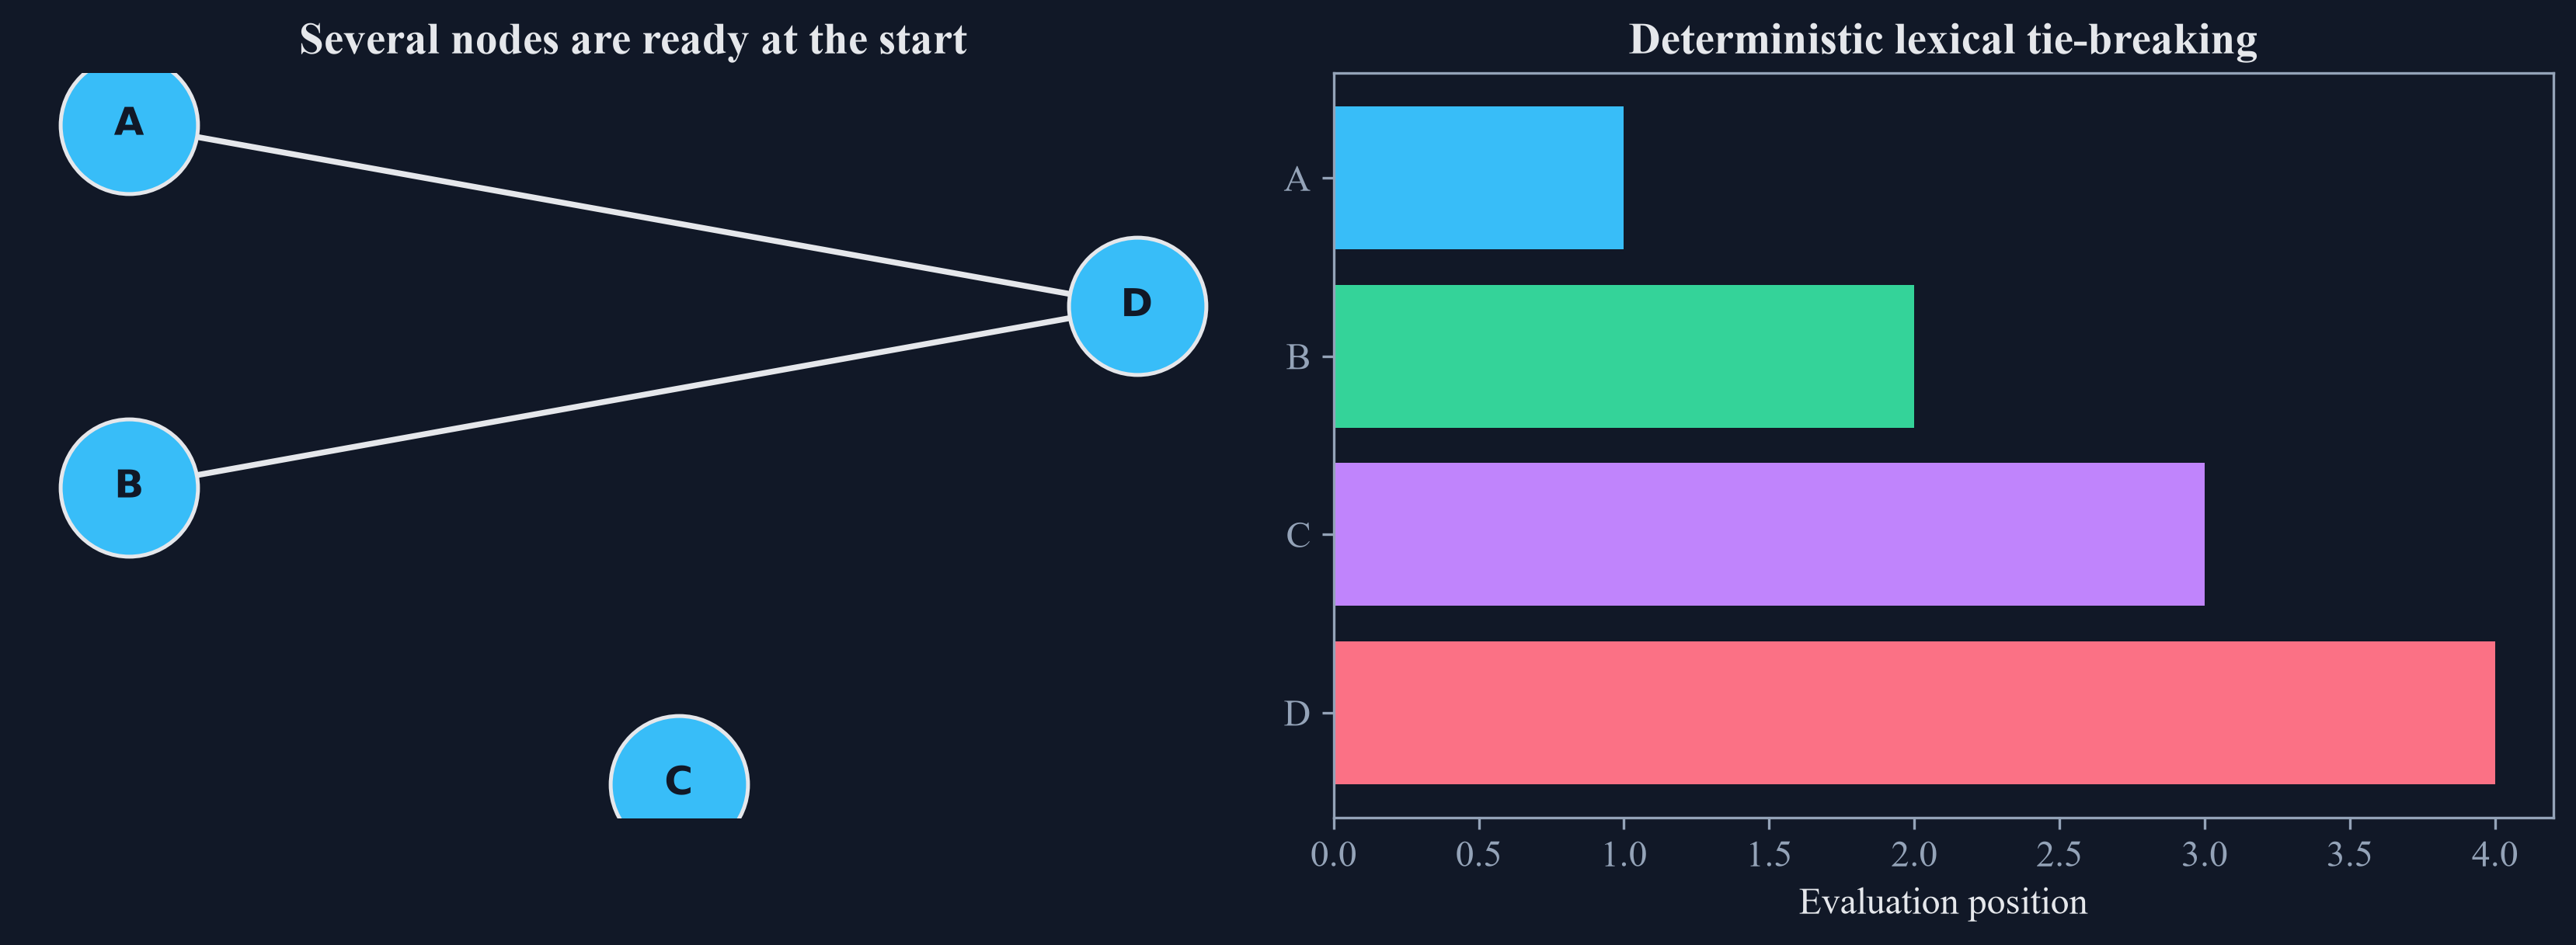

In [2]:
lexical_dag = CausalDAG(("D", "C", "B", "A"), (("B", "D"), ("A", "D")), ("D", "C", "B", "A"))
captured_parents = []
def d_mechanism(parents, noise):
    captured_parents.append(parents.copy())
    return parents[:, 0] + 10.0 * parents[:, 1] + noise
lexical_result = evaluate_structural_causal_model(
    lexical_dag,
    {"D": d_mechanism, "C": lambda parents, noise: noise, "B": lambda parents, noise: noise, "A": lambda parents, noise: noise},
    {"D": [0.0, 0.0], "C": [30.0, 31.0], "B": [20.0, 21.0], "A": [1.0, 2.0]},
)
lexical_values = pd.DataFrame(lexical_result.values, columns=lexical_result.node_order)
lexical_order_table = pd.DataFrame([{"Position": index + 1, "Node": node} for index, node in enumerate(lexical_result.node_order)])
parent_order_table = pd.DataFrame(captured_parents[0], columns=["Parent A", "Parent B"])
parent_order_table["D result"] = lexical_values["D"]
save_table(lexical_order_table, "scm_lexical_order", "Lexically resolved topological order.", "tab:chapter25-scm-lexical-order")
save_table(parent_order_table, "scm_parent_order", "Parent columns supplied to the mechanism for D.", "tab:chapter25-scm-parent-order")
display(lexical_order_table)
display(parent_order_table)

positions = {"A": (0, 1), "B": (0, -0.1), "C": (1.2, -1), "D": (2.2, 0.45)}
figure, axes = plt.subplots(1, 2, figsize=(11.2, 4.2))
draw_dag(axes[0], lexical_dag, positions, "Several nodes are ready at the start")
axes[1].barh(lexical_order_table["Node"], lexical_order_table["Position"], color=[palette["cyan"], palette["green"], palette["violet"], palette["rose"]])
axes[1].invert_yaxis()
axes[1].set_xlabel("Evaluation position")
axes[1].set_title("Deterministic lexical tie-breaking")
figure.tight_layout()
save_figure(figure, "scm_lexical_order")

## Intervention replaces one mechanism

Setting $X$ to a fixed value replaces its structural equation and leaves the remaining equations unchanged:

$$
\mathcal M_{\operatorname{do}(X=x)}
=\left\{X:=x,\ M:=0.8X+U_M,\ Y:=0.7M+0.4X+U_Y\right\}.
$$

Here, $\mathcal M_{\operatorname{do}(X=x)}$ is the intervened model, $x$ is the imposed treatment value, $M$ is the mediator, $Y$ is the outcome, and $U_M$ and $U_Y$ are the unchanged outside inputs.

,Variable,Mean under do(X=0),Mean under do(X=1),Mean difference
0,X,0,1,1
1,M,-0.010573,0.789427,0.8
2,Y,-0.016716,0.943284,0.96


,Path,Effect
0,Direct X to Y,0.4
1,Mediated X to M to Y,0.56
2,Total,0.96
3,Evaluated mean difference,0.96


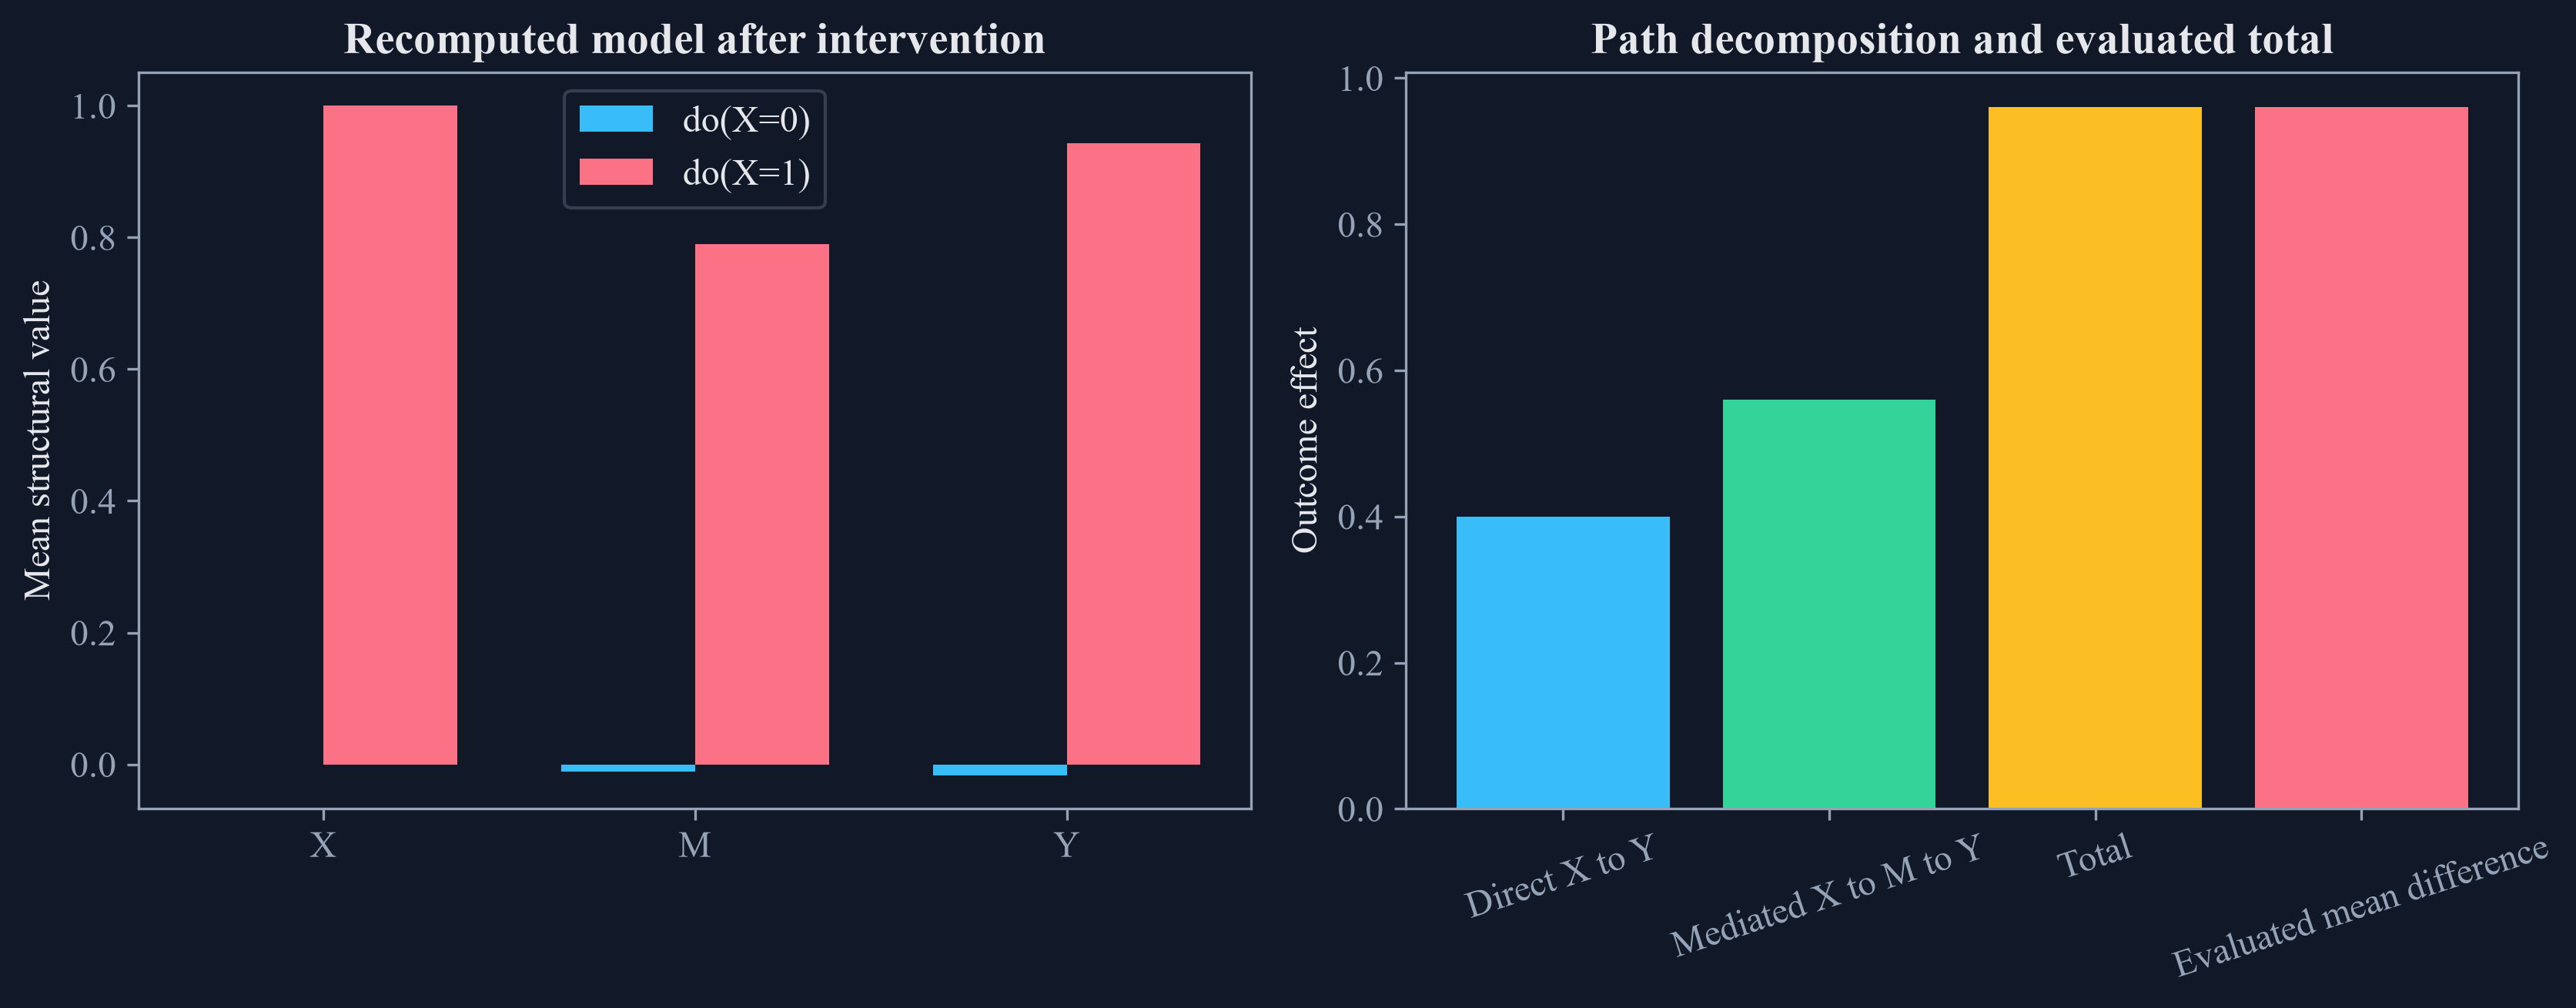

In [3]:
def intervened_result(level):
    mechanisms = dict(chain_mechanisms)
    mechanisms["X"] = lambda parents, noise: np.full(noise.shape, level)
    return evaluate_structural_causal_model(chain_dag, mechanisms, chain_exogenous)

control_result = intervened_result(0.0)
treated_result = intervened_result(1.0)
control_frame = pd.DataFrame(control_result.values, columns=control_result.node_order)
treated_frame = pd.DataFrame(treated_result.values, columns=treated_result.node_order)
outcome_effects = treated_frame["Y"] - control_frame["Y"]
mediator_effects = treated_frame["M"] - control_frame["M"]
intervention_summary = pd.DataFrame([
    {"Variable": "X", "Mean under do(X=0)": control_frame["X"].mean(), "Mean under do(X=1)": treated_frame["X"].mean(), "Mean difference": treated_frame["X"].mean() - control_frame["X"].mean()},
    {"Variable": "M", "Mean under do(X=0)": control_frame["M"].mean(), "Mean under do(X=1)": treated_frame["M"].mean(), "Mean difference": mediator_effects.mean()},
    {"Variable": "Y", "Mean under do(X=0)": control_frame["Y"].mean(), "Mean under do(X=1)": treated_frame["Y"].mean(), "Mean difference": outcome_effects.mean()},
])
path_effects = pd.DataFrame([
    {"Path": "Direct X to Y", "Effect": 0.4},
    {"Path": "Mediated X to M to Y", "Effect": 0.8 * 0.7},
    {"Path": "Total", "Effect": 0.4 + 0.8 * 0.7},
    {"Path": "Evaluated mean difference", "Effect": outcome_effects.mean()},
])
save_table(intervention_summary, "scm_intervention_summary", "Structural values under two interventions.", "tab:chapter25-scm-intervention-summary")
save_table(path_effects, "scm_path_effects", "Direct, mediated, total, and evaluated effects.", "tab:chapter25-scm-path-effects")
display(intervention_summary)
display(path_effects)

figure, axes = plt.subplots(1, 2, figsize=(11.4, 4.5))
axes[0].bar(intervention_summary["Variable"], intervention_summary["Mean under do(X=0)"], width=0.36, color=palette["cyan"], label="do(X=0)")
axes[0].bar(np.arange(3) + 0.36, intervention_summary["Mean under do(X=1)"], width=0.36, color=palette["rose"], label="do(X=1)")
axes[0].set_xticks(np.arange(3) + 0.18, intervention_summary["Variable"])
axes[0].set_ylabel("Mean structural value")
axes[0].set_title("Recomputed model after intervention")
axes[0].legend()
axes[1].bar(path_effects["Path"], path_effects["Effect"], color=[palette["cyan"], palette["green"], palette["amber"], palette["rose"]])
axes[1].set_ylabel("Outcome effect")
axes[1].set_title("Path decomposition and evaluated total")
axes[1].tick_params(axis="x", rotation=18)
figure.tight_layout()
save_figure(figure, "scm_intervention_effects")

## Intervening in a nonlinear causal fork

A nonlinear three-node model can be written as:

$$
A=U_A,
\qquad
B=\sin(A)+U_B,
\qquad
C=AB+U_C.
$$

Here, $A$, $B$, and $C$ are endogenous variables, $U_A$, $U_B$, and $U_C$ are their outside inputs, $\sin$ is the sine function, and the product $AB$ makes the outcome mechanism nonlinear in its two parents.

,Node,Mean,Standard deviation,Minimum,Maximum
0,A,0,1.735767,-3,3
1,B,0.004333,0.744644,-1.463973,1.461145
2,C,1.038922,0.742417,-0.845172,3.025665


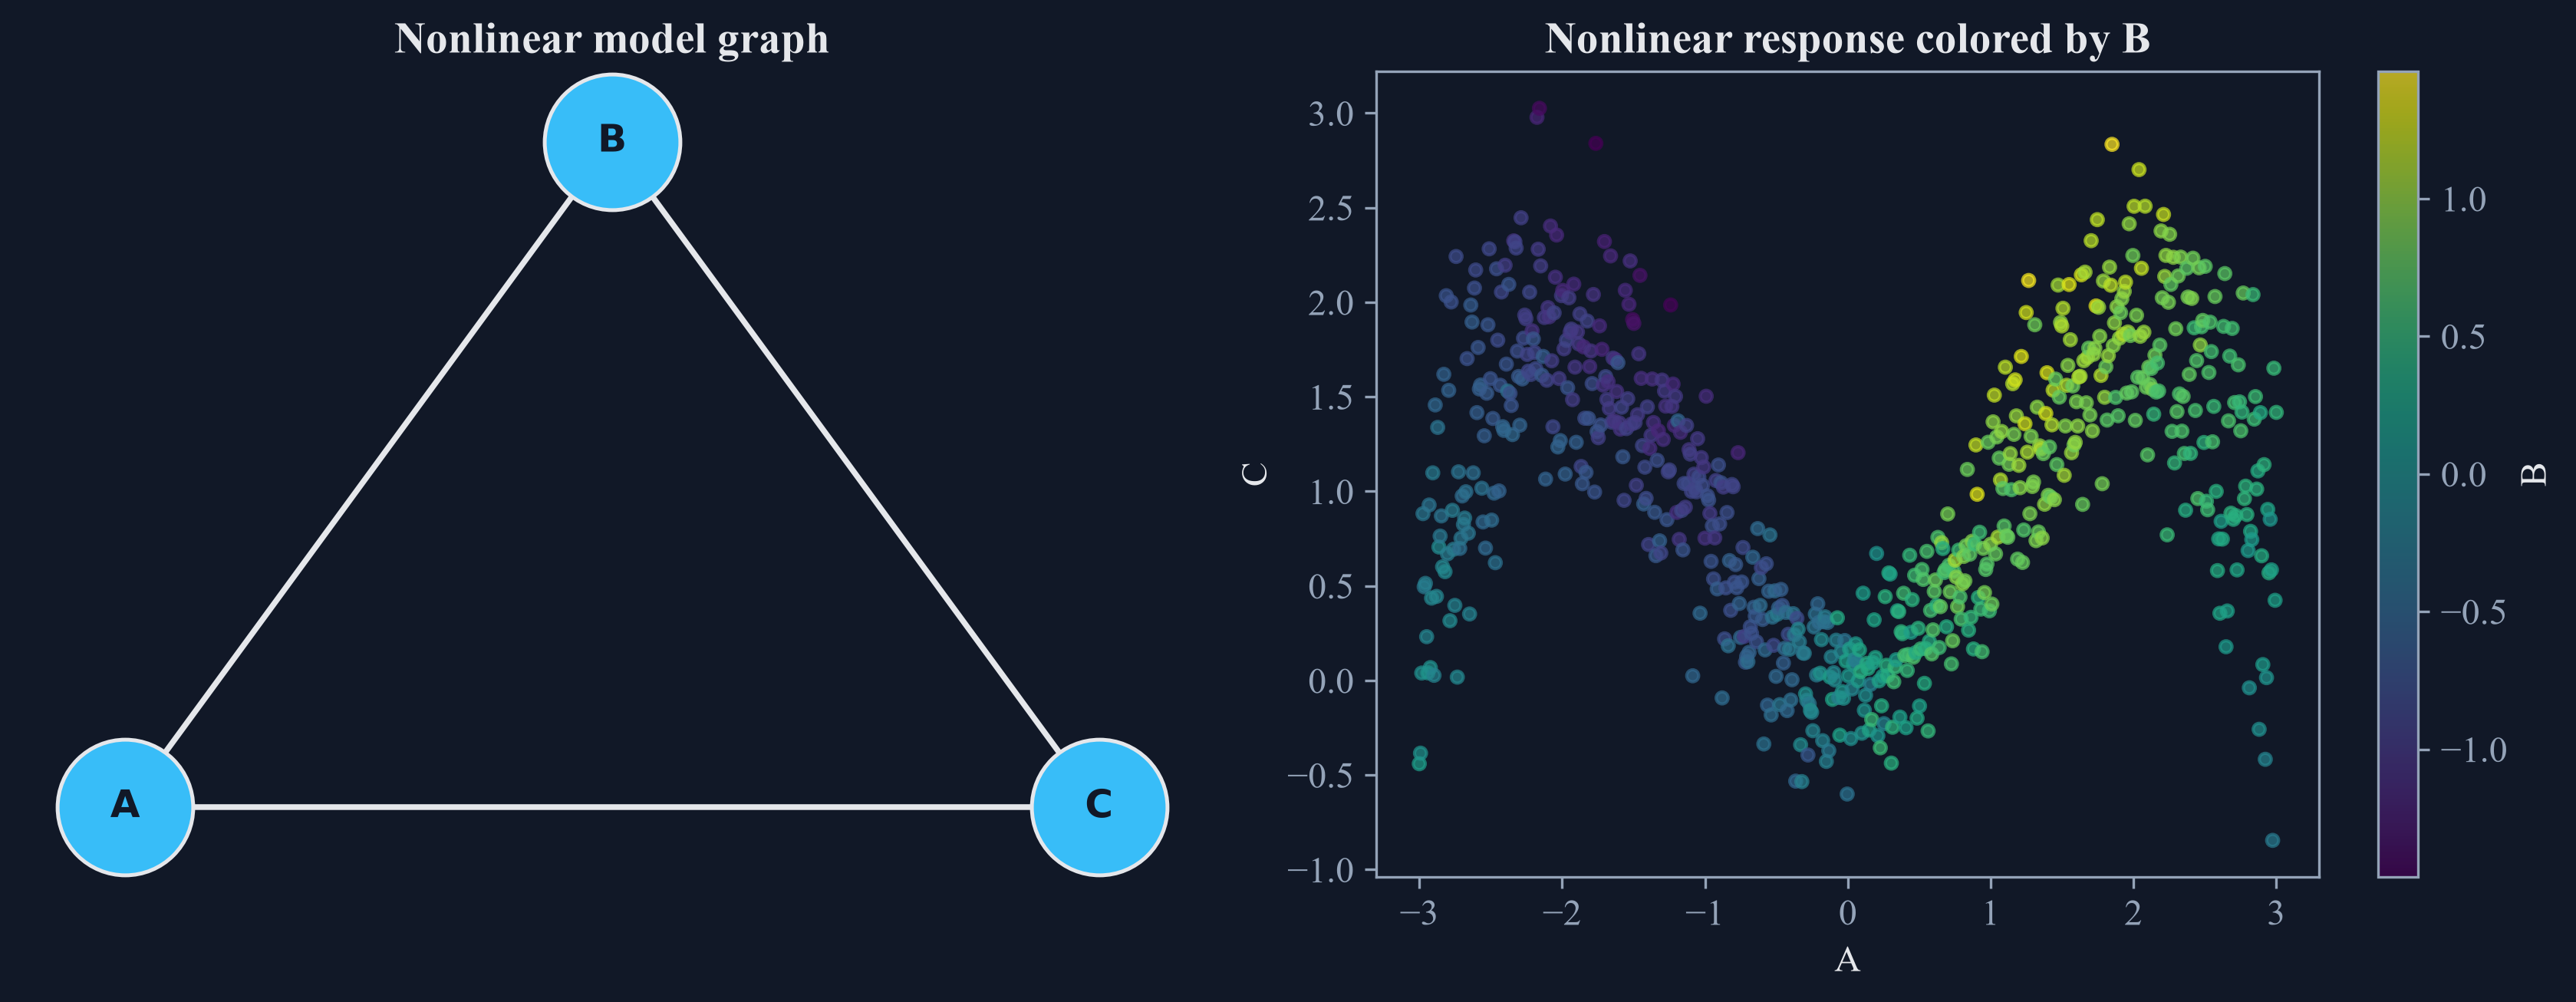

,Quantity,Value
0,Correlation C and X,0.677965
1,Correlation C and Y,0.729628
2,Unadjusted X coefficient,0.882049
3,C-adjusted X coefficient,0.507154
4,Known direct X effect,0.5


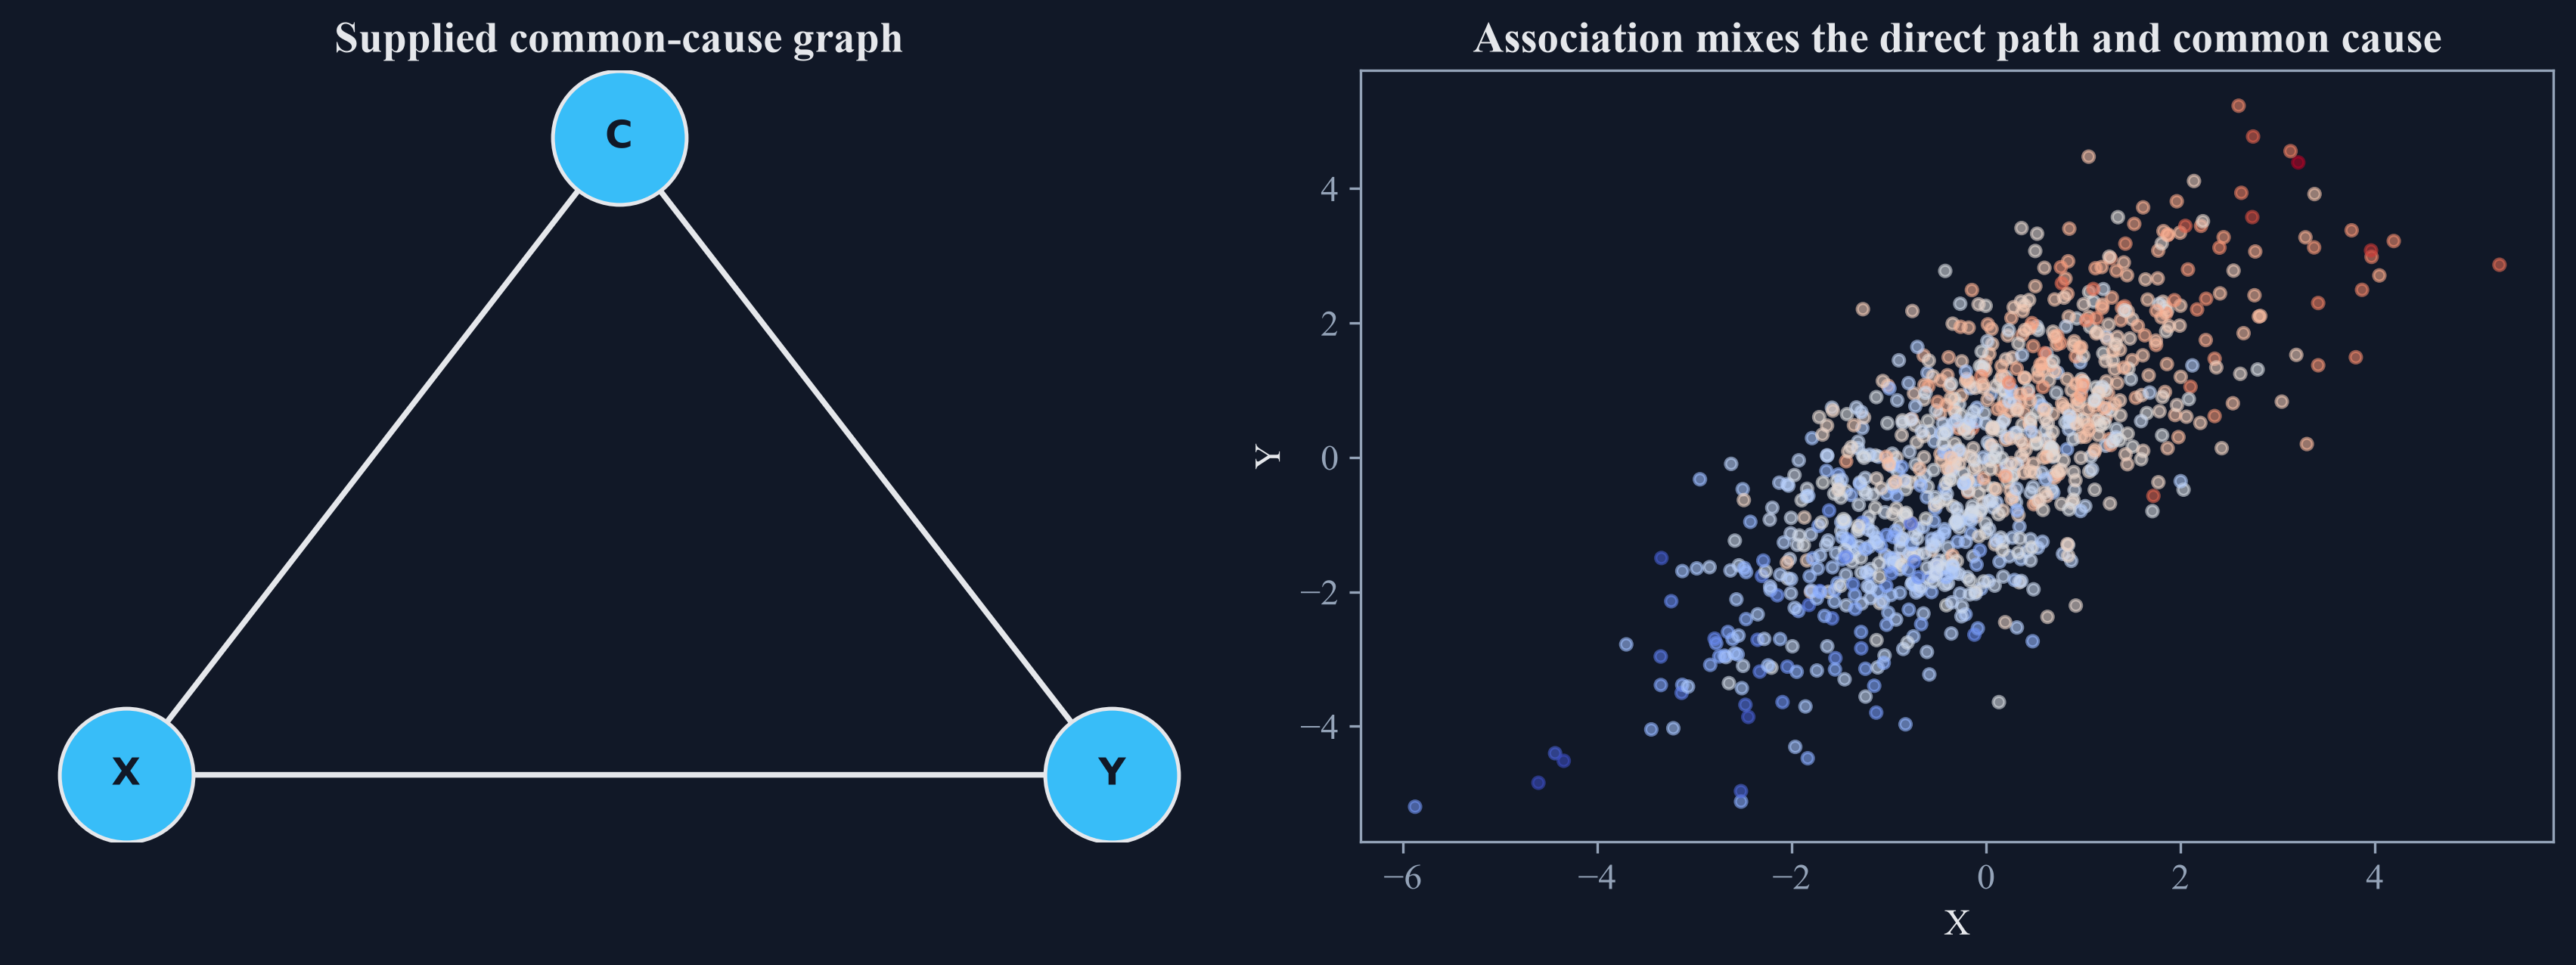

In [4]:
nonlinear_dag = CausalDAG(("A", "B", "C"), (("A", "B"), ("A", "C"), ("B", "C")), ("A", "B", "C"))
nonlinear_exogenous = {"A": np.linspace(-3.0, 3.0, 700), "B": rng.normal(scale=0.18, size=700), "C": rng.normal(scale=0.25, size=700)}
nonlinear_result = evaluate_structural_causal_model(
    nonlinear_dag,
    {"A": lambda parents, noise: noise, "B": lambda parents, noise: np.sin(parents[:, 0]) + noise, "C": lambda parents, noise: parents[:, 0] * parents[:, 1] + noise},
    nonlinear_exogenous,
)
nonlinear_frame = pd.DataFrame(nonlinear_result.values, columns=nonlinear_result.node_order)
nonlinear_summary = nonlinear_frame.agg(["mean", "std", "min", "max"]).T.reset_index().rename(columns={"index": "Node", "mean": "Mean", "std": "Standard deviation", "min": "Minimum", "max": "Maximum"})
save_table(nonlinear_summary, "scm_nonlinear_summary", "Summary of the nonlinear structural model.", "tab:chapter25-scm-nonlinear-summary")
display(nonlinear_summary)

figure, axes = plt.subplots(1, 2, figsize=(11.5, 4.5))
draw_dag(axes[0], nonlinear_dag, {"A": (0, 0), "B": (1.1, 0.8), "C": (2.2, 0)}, "Nonlinear model graph")
scatter = axes[1].scatter(nonlinear_frame["A"], nonlinear_frame["C"], c=nonlinear_frame["B"], cmap="viridis", s=14, alpha=0.7)
axes[1].set_xlabel("A")
axes[1].set_ylabel("C")
axes[1].set_title("Nonlinear response colored by B")
figure.colorbar(scatter, ax=axes[1], label="B")
figure.tight_layout()
save_figure(figure, "scm_nonlinear_graph_and_response")

fork_dag = CausalDAG(("C", "X", "Y"), (("C", "X"), ("C", "Y"), ("X", "Y")), ("C", "X", "Y"))
fork_inputs = {"C": rng.normal(size=1000), "X": rng.normal(size=1000), "Y": rng.normal(size=1000)}
fork_result = evaluate_structural_causal_model(fork_dag, {"C": lambda parents, noise: noise, "X": lambda parents, noise: 0.9 * parents[:, 0] + noise, "Y": lambda parents, noise: 0.7 * parents[:, 0] + 0.5 * parents[:, 1] + noise}, fork_inputs)
fork_frame = pd.DataFrame(fork_result.values, columns=fork_result.node_order)
fork_relationships = pd.DataFrame([
    {"Quantity": "Correlation C and X", "Value": fork_frame[["C", "X"]].corr().iloc[0, 1]},
    {"Quantity": "Correlation C and Y", "Value": fork_frame[["C", "Y"]].corr().iloc[0, 1]},
    {"Quantity": "Unadjusted X coefficient", "Value": ols_coefficient(fork_frame["Y"], fork_frame["X"])},
    {"Quantity": "C-adjusted X coefficient", "Value": ols_coefficient(fork_frame["Y"], fork_frame["X"], fork_frame["C"])},
    {"Quantity": "Known direct X effect", "Value": 0.5},
])
save_table(fork_relationships, "scm_fork_relationships", "Relationships and treatment coefficients in a supplied fork model.", "tab:chapter25-scm-fork")
display(fork_relationships)

figure, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
draw_dag(axes[0], fork_dag, {"C": (0.9, 1), "X": (0, 0), "Y": (1.8, 0)}, "Supplied common-cause graph")
axes[1].scatter(fork_frame["X"], fork_frame["Y"], c=fork_frame["C"], cmap="coolwarm", s=13, alpha=0.58)
axes[1].set_xlabel("X")
axes[1].set_ylabel("Y")
axes[1].set_title("Association mixes the direct path and common cause")
figure.tight_layout()
save_figure(figure, "scm_fork_graph_and_association")

## Protecting supplied inputs while rejecting invalid cases

In [5]:
protected_observations = []
def protected_root(parents, noise):
    protected_observations.append({"Parent shape": str(parents.shape), "Parents writable": parents.flags.writeable, "Outside input writable": noise.flags.writeable})
    return noise
protected_dag = CausalDAG(("X",), (), ("X",))
source_values = np.array([1.0, 2.0])
output_values = source_values.copy()
protected_result = evaluate_structural_causal_model(protected_dag, {"X": protected_root}, {"X": source_values})
source_values[:] = 10.0
output_values[:] = 20.0
protection_table = pd.DataFrame(protected_observations)
protection_table["Result writable"] = protected_result.values.flags.writeable
protection_table["Stored first value after outside mutation"] = protected_result.values[0, 0]
save_table(protection_table, "scm_protection_checks", "Protected input and result behavior.", "tab:chapter25-scm-protection")
display(protection_table)

one_node = CausalDAG(("X",), (), ("X",))
two_nodes = CausalDAG(("X", "Y"), (("X", "Y"),), ("X", "Y"))
failure_checks = pd.DataFrame([
    contract_result("Wrong graph type", lambda: evaluate_structural_causal_model("X", {"X": lambda parents, noise: noise}, {"X": [1.0]}), "TypeError"),
    contract_result("Mechanisms not a mapping", lambda: evaluate_structural_causal_model(one_node, (), {"X": [1.0]}), "TypeError"),
    contract_result("Missing mechanism", lambda: evaluate_structural_causal_model(one_node, {}, {"X": [1.0]}), "ValueError"),
    contract_result("Noncallable mechanism", lambda: evaluate_structural_causal_model(one_node, {"X": 1}, {"X": [1.0]}), "TypeError"),
    contract_result("Empty outside input", lambda: evaluate_structural_causal_model(one_node, {"X": lambda parents, noise: noise}, {"X": []}), "ValueError"),
    contract_result("Two-dimensional outside input", lambda: evaluate_structural_causal_model(one_node, {"X": lambda parents, noise: noise}, {"X": [[1.0]]}), "ValueError"),
    contract_result("Boolean outside input", lambda: evaluate_structural_causal_model(one_node, {"X": lambda parents, noise: noise}, {"X": [True]}), "ValueError"),
    contract_result("Nonfinite outside input", lambda: evaluate_structural_causal_model(one_node, {"X": lambda parents, noise: noise}, {"X": [np.inf]}), "ValueError"),
    contract_result("Unequal outside-input lengths", lambda: evaluate_structural_causal_model(two_nodes, {"X": lambda parents, noise: noise, "Y": lambda parents, noise: noise}, {"X": [1.0], "Y": [1.0, 2.0]}), "ValueError"),
    contract_result("Scalar mechanism result", lambda: evaluate_structural_causal_model(one_node, {"X": lambda parents, noise: 1.0}, {"X": [0.0]}), "ValueError"),
    contract_result("Wrong-length mechanism result", lambda: evaluate_structural_causal_model(one_node, {"X": lambda parents, noise: [1.0, 2.0]}, {"X": [0.0]}), "ValueError"),
    contract_result("Nonfinite mechanism result", lambda: evaluate_structural_causal_model(one_node, {"X": lambda parents, noise: [np.nan]}, {"X": [0.0]}), "ValueError"),
    contract_result("Cyclic graph declaration", lambda: CausalDAG(("X", "Y"), (("X", "Y"), ("Y", "X")), ("X", "Y")), "ValueError"),
    contract_result("Mechanism failure passes through", lambda: evaluate_structural_causal_model(one_node, {"X": lambda parents, noise: (_ for _ in ()).throw(RuntimeError("mechanism failed"))}, {"X": [0.0]}), "RuntimeError"),
])
scm_summary = pd.DataFrame([
    {"Question": "Who supplies the graph?", "Answer": "The caller"},
    {"Question": "Who supplies the mechanisms?", "Answer": "The caller"},
    {"Question": "Does evaluation discover a graph?", "Answer": "No"},
    {"Question": "What makes the result repeatable?", "Answer": "Fixed inputs, mechanisms, and lexical order"},
    {"Question": "How is an intervention represented?", "Answer": "Replace one mechanism and recompute descendants"},
])
save_table(failure_checks, "scm_failure_checks", "Boundary and failure checks for deterministic structural evaluation.", "tab:chapter25-scm-failure-checks")
save_table(scm_summary, "scm_section_summary", "Main conclusions from the structural-model experiments.", "tab:chapter25-scm-summary")
display(failure_checks)
display(scm_summary)

,Parent shape,Parents writable,Outside input writable,Result writable,Stored first value after outside mutation
0,"(2, 0)",False,False,False,1


,Check,Expected result,Observed result,Passed
0,Wrong graph type,TypeError,TypeError,True
1,Mechanisms not a mapping,TypeError,TypeError,True
2,Missing mechanism,ValueError,ValueError,True
3,Noncallable mechanism,TypeError,TypeError,True
4,Empty outside input,ValueError,ValueError,True
5,Two-dimensional outside input,ValueError,ValueError,True
6,Boolean outside input,ValueError,ValueError,True
7,Nonfinite outside input,ValueError,ValueError,True
8,Unequal outside-input lengths,ValueError,ValueError,True
9,Scalar mechanism result,ValueError,ValueError,True


,Question,Answer
0,Who supplies the graph?,The caller
1,Who supplies the mechanisms?,The caller
2,Does evaluation discover a graph?,No
3,What makes the result repeatable?,"Fixed inputs, mechanisms, and lexical order"
4,How is an intervention represented?,Replace one mechanism and recompute descendants


## Tests

In [6]:
assert isinstance(chain_result, StructuralCausalModelResult)
assert chain_result.node_order == ("X", "M", "Y")
assert np.allclose(chain_result.values, manual_values)
assert lexical_result.node_order == ("A", "B", "C", "D")
assert np.array_equal(captured_parents[0], [[1.0, 20.0], [2.0, 21.0]])
assert np.array_equal(lexical_values["D"], [201.0, 212.0])
assert np.allclose(mediator_effects, 0.8)
assert np.allclose(outcome_effects, 0.96)
assert not protected_result.values.flags.writeable
assert protected_result.values[0, 0] == 1.0
assert abs(fork_relationships.iloc[3]["Value"] - 0.5) < 0.08
assert failure_checks["Passed"].all()
for stem in ["scm_chain_graph_and_values", "scm_lexical_order", "scm_intervention_effects", "scm_nonlinear_graph_and_response", "scm_fork_graph_and_association"]:
    assert (FIGURES / f"{stem}.pdf").is_file()
for stem in ["scm_chain_specification", "scm_chain_summary", "scm_chain_checks", "scm_lexical_order", "scm_parent_order", "scm_intervention_summary", "scm_path_effects", "scm_nonlinear_summary", "scm_fork_relationships", "scm_protection_checks", "scm_failure_checks", "scm_section_summary"]:
    assert (TABLES / f"{stem}.tex").is_file()